**HW2
Chelsea Ankenbrandt**

**Question 1**

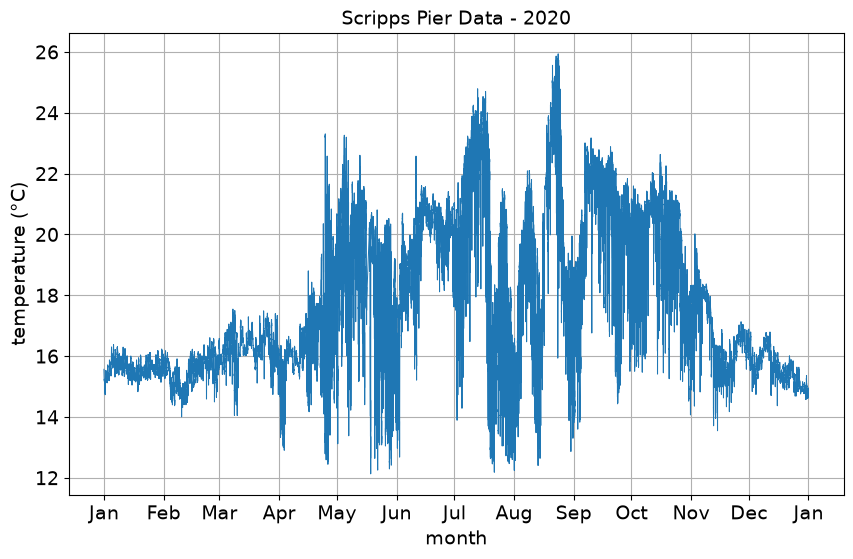

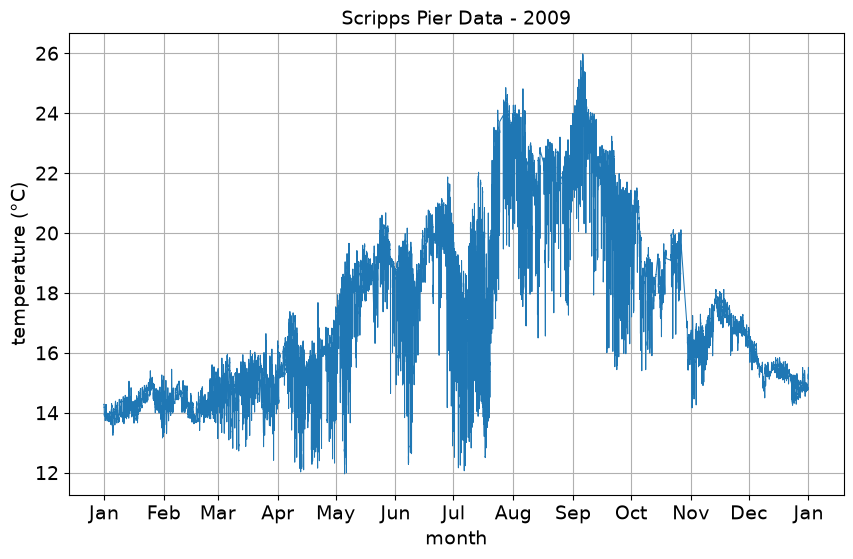

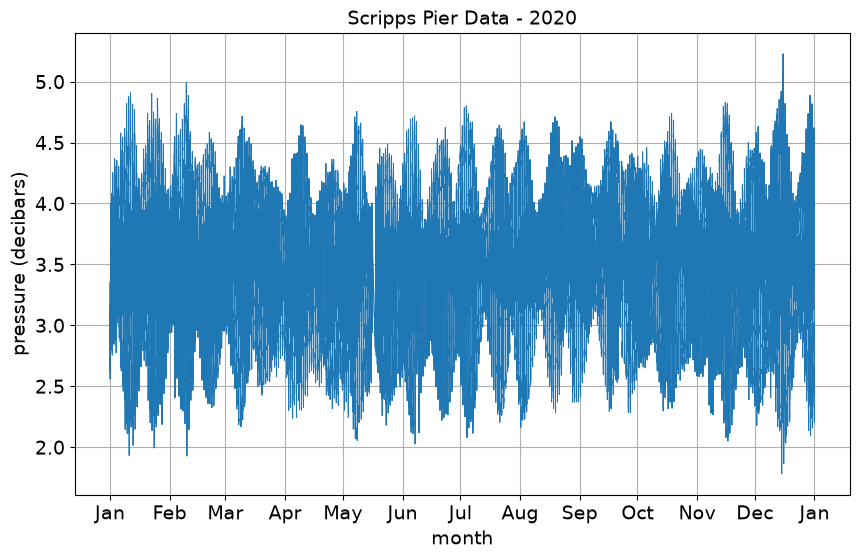

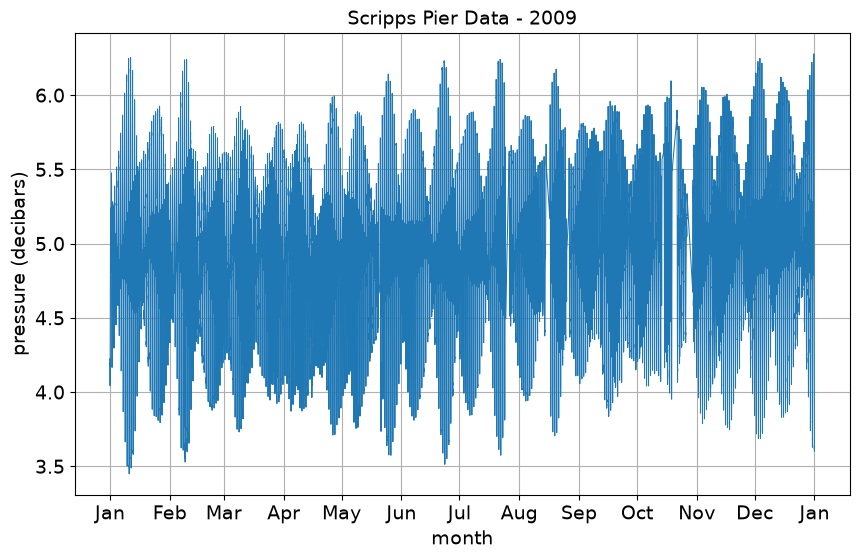

In [13]:
import os
from dataclasses import dataclass, field

import numpy as np
from netCDF4 import Dataset
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from get_xyear_pier_data import get_pier_data

temp_2020 = get_pier_data(xyear=2020)
temp_2009 = get_pier_data(xyear=2009)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(temp_2020.dnum, temp_2020.temperature, linewidth=.75)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.tick_params(labelsize=14)
ax.set_xlabel('month', fontsize=14)
ax.set_ylabel('temperature (°C)', fontsize=14)
ax.set_title('Scripps Pier Data - 2020', fontsize=14)
ax.grid(True)

fig, ax1 = plt.subplots(figsize=(10, 6))
ax1.plot(temp_2009.dnum, temp_2009.temperature, linewidth=.75)
ax1.xaxis.set_major_locator(mdates.MonthLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax1.tick_params(labelsize=14)
ax1.set_xlabel('month', fontsize=14)
ax1.set_ylabel('temperature (°C)', fontsize=14)
ax1.set_title('Scripps Pier Data - 2009', fontsize=14)
ax1.grid(True)

fig, ax2 = plt.subplots(figsize=(10, 6))
ax2.plot(temp_2020.dnum, temp_2020.pressure, linewidth=.75)
ax2.xaxis.set_major_locator(mdates.MonthLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax2.tick_params(labelsize=14)
ax2.set_xlabel('month', fontsize=14)
ax2.set_ylabel('pressure (decibars)', fontsize=14)
ax2.set_title('Scripps Pier Data - 2020', fontsize=14)
ax2.grid(True)

fig, ax3 = plt.subplots(figsize=(10, 6))
ax3.plot(temp_2009.dnum, temp_2009.pressure, linewidth=.75)
ax3.xaxis.set_major_locator(mdates.MonthLocator())
ax3.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax3.tick_params(labelsize=14)
ax3.set_xlabel('month', fontsize=14)
ax3.set_ylabel('pressure (decibars)', fontsize=14)
ax3.set_title('Scripps Pier Data - 2009', fontsize=14)
ax3.grid(True)
plt.show()


In 2020, there was an earlier temperature jump in May/June that isn't replicated in 2009. Otherwise, the two relatively follow the same trends. They both experienced some summer upwelling, and reached their highest temperatures towards the end of September/beginning of October. I notice a few gaps in the 2009 data, visible even from the yearly graphs.
Pressure looks very similar on both, except for the different sections with gaps between the two data sets.

**Question 2**

In [6]:
import os
from dataclasses import dataclass, field
import random
from scipy.stats import uniform


import numpy as np
from netCDF4 import Dataset
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from get_xyear_pier_data import get_pier_data, PierData

temp_2020_avg = np.mean(temp_2020.temperature)
temp_2009_avg = np.mean(temp_2009.temperature)

print(f'2020 mean temperature: {temp_2020_avg: .5g}')
print(f'2009 mean temperature: {temp_2009_avg: .5g}')

temp_2020_sem = np.std(temp_2020.temperature, ddof=1) / np.sqrt(len(temp_2020.temperature))
temp_2009_sem = np.std(temp_2009.temperature, ddof=1) / np.sqrt(len(temp_2009.temperature))

print(f'2020 standard error of mean: {temp_2020_sem: .3g}')
print(f'2009 standard error of mean: {temp_2009_sem: .3g}')

print(f'The difference in means: {temp_2020_avg - temp_2009_avg: .3g}')

if (temp_2020_avg - temp_2009_avg) > (temp_2020_sem + temp_2009_sem):
    print('The difference in means is outside of the standard error of means')
else:
    print('The difference in means is within the standard error of means. \n')

#AI disclosure - I had a version of this function that wouldn't work for a crazy long time, I used Claude to fix it! 
def subsample_pier_data(pier, hour):
    # calendar day of each sample
    day = pier.dnum.astype('datetime64[D]')
    after_hour = pier.dnum >= day + np.timedelta64(hour, 'h')

    #indices of samples after the hour
    idx_after = np.flatnonzero(after_hour)                  

    #returns the first occurrence of each day after the hour
    _, first = np.unique(day[idx_after], return_index=True)
    idx = idx_after[first]
    return PierData(dnum=pier.dnum[idx],
                    temperature=pier.temperature[idx],
                    pressure=pier.pressure[idx])

subsample_2020 = subsample_pier_data(temp_2020, hour=0)
subsample_2009 = subsample_pier_data(temp_2009, hour=0)

daily_2020_average = np.mean(subsample_2020.temperature)
daily_2009_average = np.mean(subsample_2009.temperature)

print(f'Daily subsampled 2020 average temperature: {daily_2020_average: .5g}')
print(f'Daily subsampled 2009 average temperature: {daily_2009_average: .5g}')

daily_2020_sem = np.std(subsample_2020.temperature, ddof=1) / np.sqrt(len(subsample_2020.temperature))
daily_2009_sem = np.std(subsample_2009.temperature, ddof=1) / np.sqrt(len(subsample_2009.temperature))

print(f'Daily subsampled 2020 standard error of mean: {daily_2020_sem: .3g}')
print(f'Daily subsampled 2009 standard error of mean: {daily_2009_sem: .3g}')


if (daily_2020_average - daily_2009_average) > (daily_2020_sem + daily_2009_sem):
    print('The difference in subsampled daily means is outside of the standard error of means')
else:
    print('The difference in subsampled daily means is within the standard error of means.')



2020 mean temperature:  17.753
2009 mean temperature:  17.356
2020 standard error of mean:  0.00707
2009 standard error of mean:  0.0118
The difference in means:  0.397
The difference in means is outside of the standard error of means
Daily subsampled 2020 average temperature:  18.364
Daily subsampled 2009 average temperature:  17.867
Daily subsampled 2020 standard error of mean:  0.137
Daily subsampled 2009 standard error of mean:  0.162
The difference in subsampled daily means is outside of the standard error of means


This one was very interesting to see! I realiezd the standard error of the mean was much greater in the 2009 dataset vs. 2020, which lead me down a rabbit hole of eventually realizing the data set is about half the size of the 2020 data set. I assume sampling frequency was increased in the interim

When I subsampled, I originally wanted to look at noon every day, as Melissa Carter had said on the pier tour that was a good neutral time not too impacted by the sun, but with gaps in the data, my 2009 data set was missing 10 days. I instead sampled at the start of each day, which I believe is 4pm here if it's in GMT. That gave me an extra 6 days back into my sample.

Even with the subsampling granting a much larger error, these two years are very different. It is not simply error that explains why 2020 is ~half a degree warmer than 2009. 

**Question 3**

In [7]:
var_2020 = np.var(temp_2020.temperature, ddof=1)
var_2009 = np.var(temp_2009.temperature, ddof=1)

print(f'2020 variance: {var_2020: .3g}')
print(f'2009 variance: {var_2009: .3g}')

#standard deviations (sigma)
sig_2020 = np.std(temp_2020.temperature, ddof=1)
sig_2009 = np.std(temp_2009.temperature, ddof=1)

#standard error of the variance
sev_2020 = sig_2020**2*np.sqrt(2/(len(temp_2020) - 1))
sev_2009 = sig_2009**2*np.sqrt(2/(len(temp_2009) - 1))

print(f'2020 standard error of the variance: {sev_2020: .3g}')
print(f'2009 standard error of the variance: {sev_2009: .3g}')

daily_2020_variance = np.var(subsample_2020.temperature, ddof=1)
daily_2009_variance = np.var(subsample_2009.temperature, ddof=1)

print(f'Daily subsampled 2020 variance: {daily_2020_variance: .3g}')
print(f'Daily subsampled 2009 variance: {daily_2009_variance: .3g}')

daily_sig_2020 = np.std(subsample_2020.temperature, ddof=1)
daily_sig_2009 = np.std(subsample_2009.temperature, ddof=1)

#standard error of the variance
daily_sev_2020 = daily_sig_2020**2*np.sqrt(2/(len(subsample_2020) - 1))
daily_sev_2009 = daily_sig_2009**2*np.sqrt(2/(len(subsample_2009) - 1))

print(f'Daily subsampled 2020 standard error of the variance: {daily_sev_2020: .3g}')
print(f'Daily subsampled 2009 standard error of the variance: {daily_sev_2009: .3g}')

2020 variance:  6.51
2009 variance:  8.8
2020 standard error of the variance:  0.0255
2009 standard error of the variance:  0.0495
Daily subsampled 2020 variance:  6.86
Daily subsampled 2009 variance:  9.52
Daily subsampled 2020 standard error of the variance:  0.508
Daily subsampled 2009 standard error of the variance:  0.71


Once again, the two data sets are significanly different, in a way that cannot be explained just by the error in the variance. I do not get different results from daily sampling 

**Question 3**

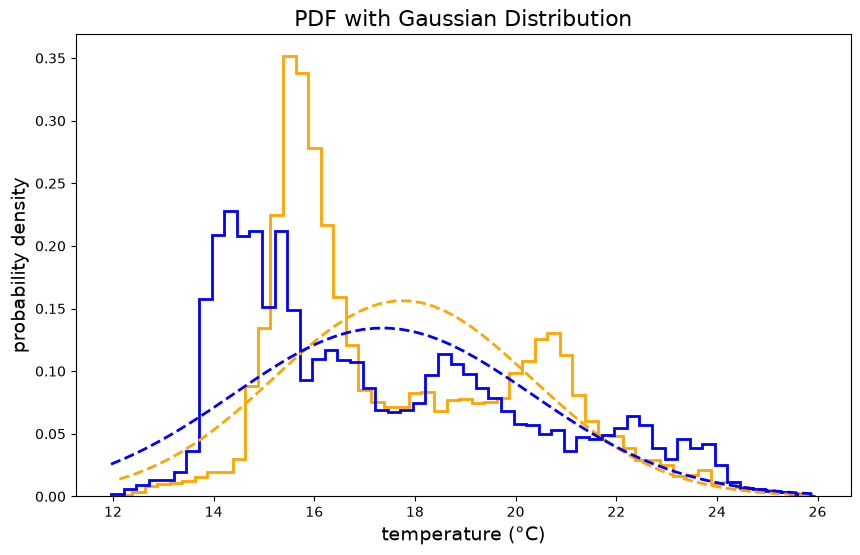

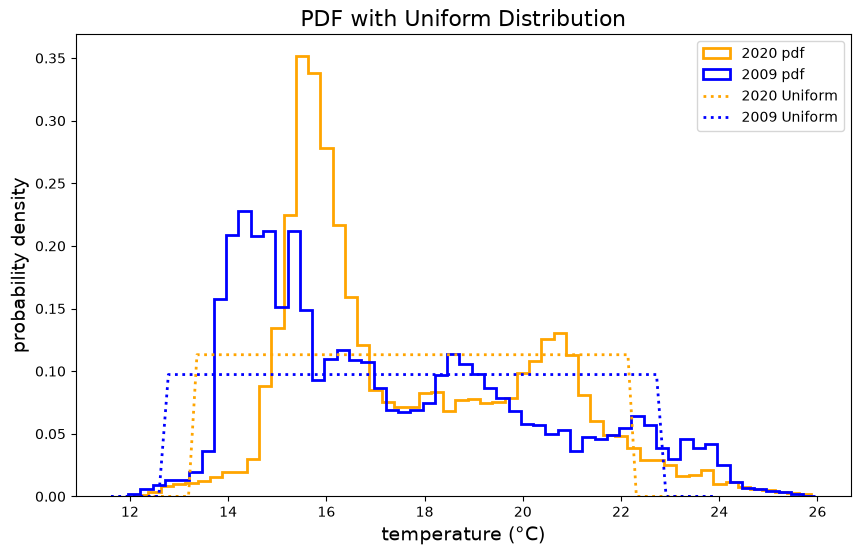

In [21]:
pdfbins_2020_temp = np.arange(temp_2020.temperature.min(), temp_2020.temperature.max(), 0.25)
pdfbins_2009_temp = np.arange(temp_2009.temperature.min(), temp_2009.temperature.max(), 0.25)

#gaussian distributions with the same mean and variance
gaus_2020 = (1.0/sig_2020/np.sqrt(2*np.pi)) * np.exp(-(pdfbins_2020_temp - temp_2020_avg)**2 / (2*sig_2020**2))
gaus_2009 = (1.0/sig_2009/np.sqrt(2*np.pi)) * np.exp(-(pdfbins_2009_temp - temp_2009_avg)**2 / (2*sig_2009**2))

# uniform distributions with the same mean and variance
width_2020 = sig_2020 * np.sqrt(12)
width_2009 = sig_2009 * np.sqrt(12)

a_2020 = temp_2020_avg - width_2020 / 2
a_2009 = temp_2020_avg - width_2009 / 2

x_2020 = np.linspace(a_2020 - 1, a_2020 + width_2020 + 1, 64)
x_2009 = np.linspace(a_2009 - 1, a_2009 + width_2009 + 1, 64)

unif_2020 = uniform.pdf(x_2020, loc=a_2020, scale=width_2020)
unif_2009 = uniform.pdf(x_2009, loc=a_2009, scale=width_2009)


fig, ax4 = plt.subplots(figsize=(10, 6))
pdf = ax4.hist(temp_2020.temperature, bins=pdfbins_2020_temp, density=True, histtype='step', edgecolor='orange', linewidth=2, label = '2020 pdf') # type: ignore
pdf = ax4.hist(temp_2009.temperature, bins=pdfbins_2009_temp, density=True, histtype='step', edgecolor='blue', linewidth=2, label = '2009 pdf') # type: ignore
ax4.plot(pdfbins_2020_temp, gaus_2020, lw=2, label='2020 Gaussian', color = 'orange', linestyle='--')
ax4.plot(pdfbins_2009_temp, gaus_2009, lw=2, label='2009 Gaussian', color = 'blue', linestyle='--')
ax4.set_ylabel('probability density', fontsize=14)
ax4.set_xlabel('temperature (°C)', fontsize=14)
ax4.set_title('PDF with Gaussian Distribution', fontsize=16)

fig, ax5 = plt.subplots(figsize=(10, 6))
pdf = ax5.hist(temp_2020.temperature, bins=pdfbins_2020_temp, density=True, histtype='step', edgecolor='orange', linewidth=2, label = '2020 pdf') # type: ignore
pdf = ax5.hist(temp_2009.temperature, bins=pdfbins_2009_temp, density=True, histtype='step', edgecolor='blue', linewidth=2, label = '2009 pdf') # type: ignore
ax5.plot(x_2020, unif_2020, lw=2, label='2020 Uniform', color = 'orange', linestyle=':')
ax5.plot(x_2009, unif_2009, lw=2, label='2009 Uniform', color = 'blue', linestyle=':')
ax5.set_ylabel('probability density', fontsize=14)
ax5.set_xlabel('temperature (°C)', fontsize=14)
ax5.set_title('PDF with Uniform Distribution', fontsize=16)
plt.legend()
plt.show()

Not sure my color choices were great, but I'm still learning all the python graphing formatting options. I chose to plot them separately since together I found the graph hard to read. 

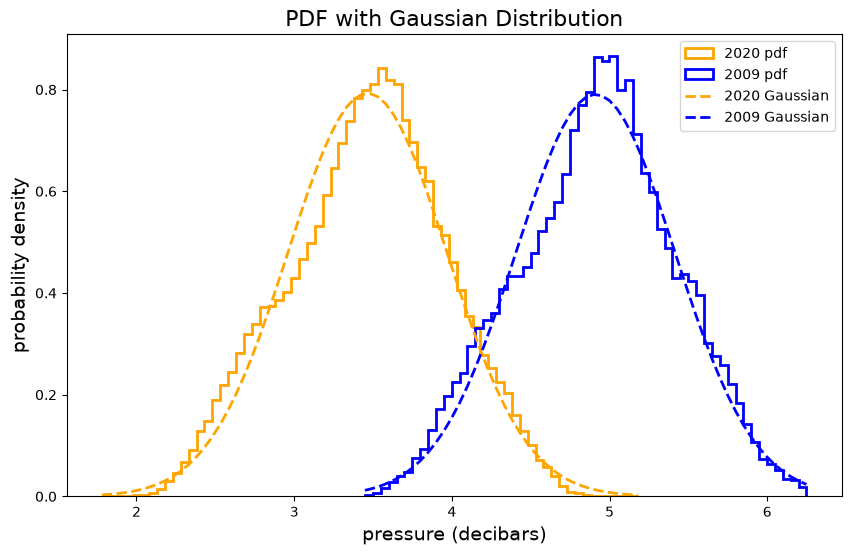

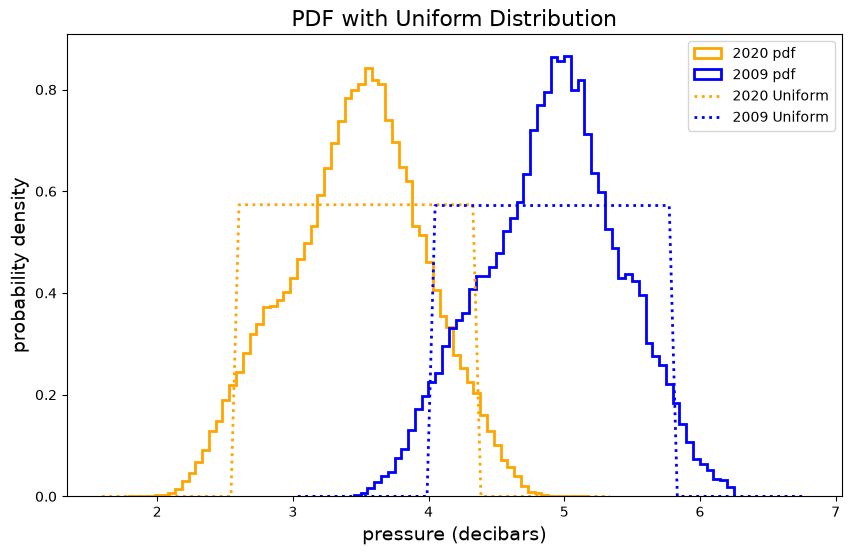

In [59]:
#do it again for pressure
pdfbins_2020_pressure = np.arange(temp_2020.pressure.min(), temp_2020.pressure.max(), 0.05)
pdfbins_2009_pressure = np.arange(temp_2009.pressure.min(), temp_2009.pressure.max(), 0.05)

pressure_sig_2020 = np.std(temp_2020.pressure, ddof=1)
pressure_sig_2009 = np.std(temp_2009.pressure, ddof=1)

pressure_2020_avg = np.mean(temp_2020.pressure)
pressure_2009_avg = np.mean(temp_2009.pressure)

pressure_gaus_2020 = (1.0/pressure_sig_2020/np.sqrt(2*np.pi)) * np.exp(-(pdfbins_2020_pressure - pressure_2020_avg)**2 / (2*pressure_sig_2020**2))
pressure_gaus_2009 = (1.0/pressure_sig_2009/np.sqrt(2*np.pi)) * np.exp(-(pdfbins_2009_pressure - pressure_2009_avg)**2 / (2*pressure_sig_2009**2))

# uniform distribution with the same mean and variance
pressure_width_2020 = pressure_sig_2020 * np.sqrt(12)
pressure_width_2009 = pressure_sig_2009 * np.sqrt(12)

pressure_a_2020 = pressure_2020_avg - pressure_width_2020 / 2
pressure_a_2009 = pressure_2009_avg - pressure_width_2009 / 2

pressure_x_2020 = np.linspace(pressure_a_2020 - 1, pressure_a_2020 + pressure_width_2020 + 1, 64)
pressure_x_2009 = np.linspace(pressure_a_2009 - 1, pressure_a_2009 + pressure_width_2009 + 1, 64)

pressure_unif_2020 = uniform.pdf(pressure_x_2020, loc=pressure_a_2020, scale=pressure_width_2020)
pressure_unif_2009 = uniform.pdf(pressure_x_2009, loc=pressure_a_2009, scale=pressure_width_2009)


fig, ax6 = plt.subplots(figsize=(10, 6))
pdf = ax6.hist(temp_2020.pressure, bins=pdfbins_2020_pressure, density=True, histtype='step', edgecolor='orange', linewidth=2, label = '2020 pdf') # type: ignore
pdf = ax6.hist(temp_2009.pressure, bins=pdfbins_2009_pressure, density=True, histtype='step', edgecolor='blue', linewidth=2, label = '2009 pdf') # type: ignore
ax6.plot(pdfbins_2020_pressure, pressure_gaus_2020, lw=2, label='2020 Gaussian', color = 'orange', linestyle='--')
ax6.plot(pdfbins_2009_pressure, pressure_gaus_2009, lw=2, label='2009 Gaussian', color = 'blue', linestyle='--')
ax6.set_ylabel('probability density', fontsize=14)
ax6.set_xlabel('pressure (decibars)', fontsize=14)
ax6.set_title('PDF with Gaussian Distribution', fontsize=16)
plt.legend()

fig, ax7 = plt.subplots(figsize=(10, 6))
pdf = ax7.hist(temp_2020.pressure, bins=pdfbins_2020_pressure, density=True, histtype='step', edgecolor='orange', linewidth=2, label = '2020 pdf') # type: ignore
pdf = ax7.hist(temp_2009.pressure, bins=pdfbins_2009_pressure, density=True, histtype='step', edgecolor='blue', linewidth=2, label = '2009 pdf') # type: ignore
ax7.plot(pressure_x_2020, pressure_unif_2020, lw=2, label='2020 Uniform', color = 'orange', linestyle=':')
ax7.plot(pressure_x_2009, pressure_unif_2009, lw=2, label='2009 Uniform', color = 'blue', linestyle=':')
ax7.set_ylabel('probability density', fontsize=14)
ax7.set_xlabel('pressure (decibars)', fontsize=14)
ax7.set_title('PDF with Uniform Distribution', fontsize=16)
plt.legend()
plt.show()

I was initially surpised at how Gaussian these pdfs of the real data are. I suppose it makes sense as the tides would be sinusoidal which would always produce more frequency around the mean than at the extremes. 

I'm also a bit surprised the average is different. My first through was change in sea level, but I immediately realized a change in the sensor location makes more sense. It was probably moved shallower in the 11 years between 2009 and 2020. 

**Question 5**

In [37]:
extreme_2020_threshold = np.std(temp_2020.temperature, ddof=1) * 3 + temp_2020_avg
extreme_2009_threshold = np.std(temp_2009.temperature, ddof=1) * 3 + temp_2009_avg

counts_2020, bin_edges_2020 = np.histogram(temp_2020.temperature, bins=512, density=True)
counts_2009, bin_edges_2009 = np.histogram(temp_2009.temperature, bins=512, density=True)

extremes_2020 = bin_edges_2020[1:] > extreme_2020_threshold
extremes_2009 = bin_edges_2009[1:] > extreme_2009_threshold

bin_widths_2020 = np.diff(bin_edges_2020)
bin_widths_2009 = np.diff(bin_edges_2009)

integral_above_2020 = np.sum(counts_2020[extremes_2020] * bin_widths_2020[extremes_2020])
integral_above_2009 = np.sum(counts_2009[extremes_2009] * bin_widths_2009[extremes_2009])

print(f'The chance of a temperature extreme value in 2020 is: {100 *integral_above_2020: .3g}%')
print(f'The chance of a temperature extreme value in 2009 is: {100 * integral_above_2009: .3g}%')

The chance of a temperature extreme value in 2020 is:  0.105%
The chance of a temperature extreme value in 2009 is:  0%


Using the actual distribution, there is a .11% chance of an extreme temperature in 2020 and a 0% chance of one in 2009. 
Now, let's look at the Gaussian with the same mean and variance: 

In [56]:
from scipy.stats import norm

p_gaus_2020 = norm.sf(extreme_2020_threshold, loc=temp_2020_avg, scale=sig_2020)
p_gaus_2009 = norm.sf(extreme_2009_threshold, loc=temp_2009_avg, scale=sig_2009)
                 
print(f'The chance of a temperature extreme value in the Gaussian distribution matching 2020 is: {100 * p_gaus_2020: .3g}%')
print(f'The chance of a temperature extreme value in the Gaussian distribution matching 2009 is: {100 * p_gaus_2009: .3g}%')

The chance of a temperature extreme value in the Gaussian distribution matching 2020 is:  0.135%
The chance of a temperature extreme value in the Gaussian distribution matching 2009 is:  0.135%


Wow, turns out the norm functionality is wonderfully useful for creating a Gaussian distribution! I manaully made the gaussian pdf earlier using the formula, which was much harder of course! .135% of values being above the third standard deviation is what's expected in a Gaussian distribution. 

Now, let's look at the CDFs. 

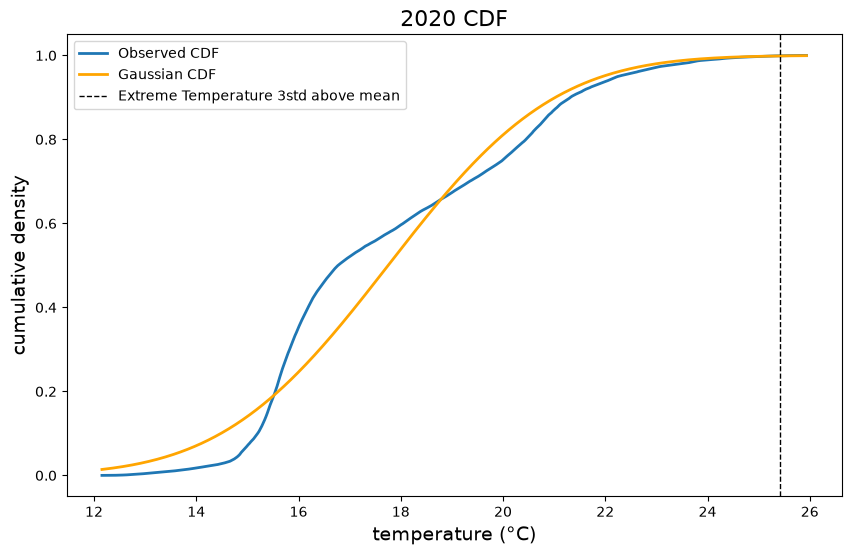

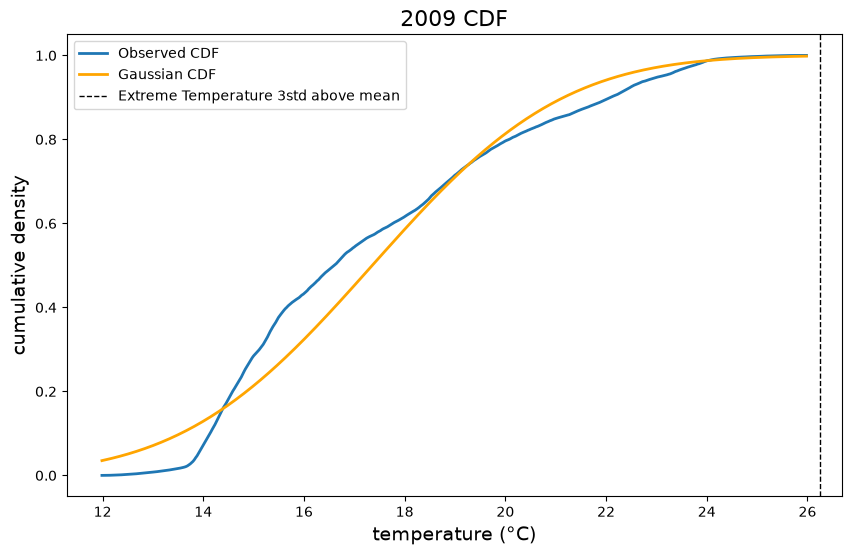

In [58]:
cdf_2020 = np.cumsum(counts_2020 *  np.diff(bin_edges_2020))
cdf_2009 = np.cumsum(counts_2009 * np.diff(bin_edges_2009))

fig, ax7 = plt.subplots(figsize=(10, 6))
ax7.plot(bin_edges_2020[1:], cdf_2020, lw=2, label='Observed CDF')
ax7.plot(bin_edges_2020[1:], norm.cdf(bin_edges_2020[1:], loc=temp_2020_avg, scale=sig_2020), lw=2, color = 'orange', label='Gaussian CDF')
ax7.axvline(extreme_2020_threshold, color='k', ls='--', lw=1, label='Extreme Temperature 3std above mean')
ax7.set_ylabel('cumulative density', fontsize=14)
ax7.set_xlabel('temperature (°C)', fontsize=14)
ax7.set_title('2020 CDF', fontsize=16)
plt.legend()

fig, ax8 = plt.subplots(figsize=(10,6))
ax8.plot(bin_edges_2009[1:], cdf_2009, lw=2, label='Observed CDF')
ax8.plot(bin_edges_2009[1:], norm.cdf(bin_edges_2009[1:], loc=temp_2009_avg, scale=sig_2009), lw=2, color = 'orange', label = 'Gaussian CDF')
ax8.axvline(extreme_2009_threshold, color='k', ls='--', lw=1, label='Extreme Temperature 3std above mean')
ax8.set_ylabel('cumulative density', fontsize=14)
ax8.set_xlabel('temperature (°C)', fontsize=14)
ax8.set_title('2009 CDF', fontsize=16)
plt.legend()
plt.show()

Here, you can see that because in 2009, 3 standard deviations above the mean is above any observed values, the temperature extreme is off the edge of what is shown clearly on the plot. In 2020, it is easier to see that a very few observed values sit above the threshold. 